In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
orders = pd.read_csv("../data/features/orders_features.csv")
customers = pd.read_csv("../data/features/customers_features.csv")
sellers = pd.read_csv("../data/features/sellers_features.csv")

In [6]:
print("Orders:", orders.shape)
print("Customers:", customers.shape)
print("Sellers:", sellers.shape)

Orders: (98666, 4)
Customers: (98666, 5)
Sellers: (3095, 3)


In [ ]:
print("Orders:", orders.info())
print("Customers:", customers.info())
print("Sellers:", sellers.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 98666 entries, 0 to 98665
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   order_id           98666 non-null  object 
 1   total_order_value  98666 non-null  float64
 2   delivery_days      96476 non-null  float64
 3   delivery_delay     96476 non-null  float64
dtypes: float64(3), object(1)
memory usage: 3.0+ MB
Orders: None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 98666 entries, 0 to 98665
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id              98666 non-null  object 
 1   customer_order_count     98666 non-null  int64  
 2   customer_total_spending  98666 non-null  float64
 3   average_order_value      98666 non-null  float64
 4   repeat_customer          98666 non-null  object 
dtypes: float64(2), int64(1), object(2)
memory usage:

In [11]:
print("Orders:", orders.describe())
print("Customers:", customers.describe())
print("Sellers:", sellers.describe())

Orders:        total_order_value  delivery_days  delivery_delay
count       98666.000000   96476.000000    96476.000000
mean          160.577638      12.497336      -11.876881
std           220.466087       9.555460       10.183854
min             9.590000       0.000000     -147.000000
25%            61.980000       7.000000      -17.000000
50%           105.290000      10.000000      -12.000000
75%           176.870000      16.000000       -7.000000
max         13664.080000     210.000000      188.000000
Customers:        customer_order_count  customer_total_spending  average_order_value
count          98666.000000             98666.000000         98666.000000
mean               1.141731               160.577638           160.577638
std                0.538452               220.466087           220.466087
min                1.000000                 9.590000             9.590000
25%                1.000000                61.980000            61.980000
50%                1.000000      

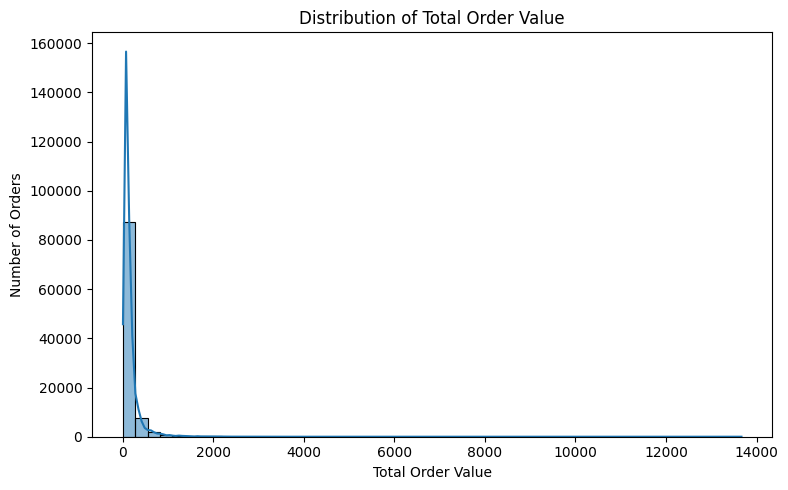

In [25]:
plt.figure(figsize=(8, 5))

sns.histplot(
    orders["total_order_value"],
    bins=50,
    kde=True
)

plt.title("Distribution of Total Order Value")
plt.xlabel("Total Order Value")
plt.ylabel("Number of Orders")

plt.tight_layout()
plt.show()

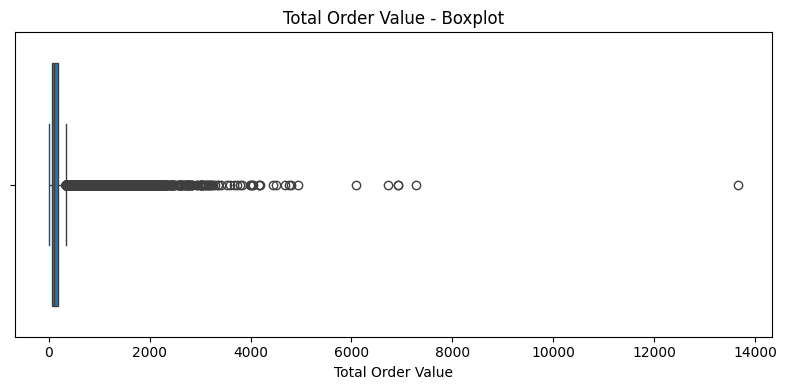

In [26]:
plt.figure(figsize=(8, 4))

sns.boxplot(
    x=orders["total_order_value"]
)

plt.title("Total Order Value - Boxplot")
plt.xlabel("Total Order Value")

plt.tight_layout()
plt.show()

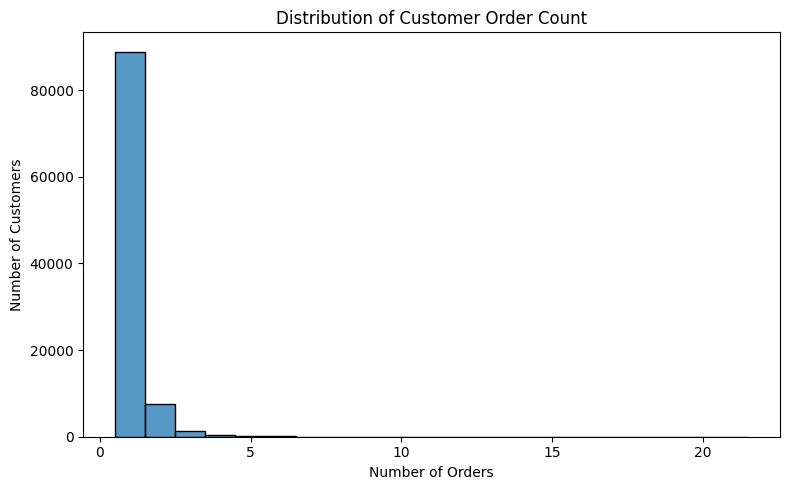

In [27]:
plt.figure(figsize=(8, 5))

sns.histplot(
    customers["customer_order_count"],
    bins=20,
    discrete=True
)

plt.title("Distribution of Customer Order Count")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

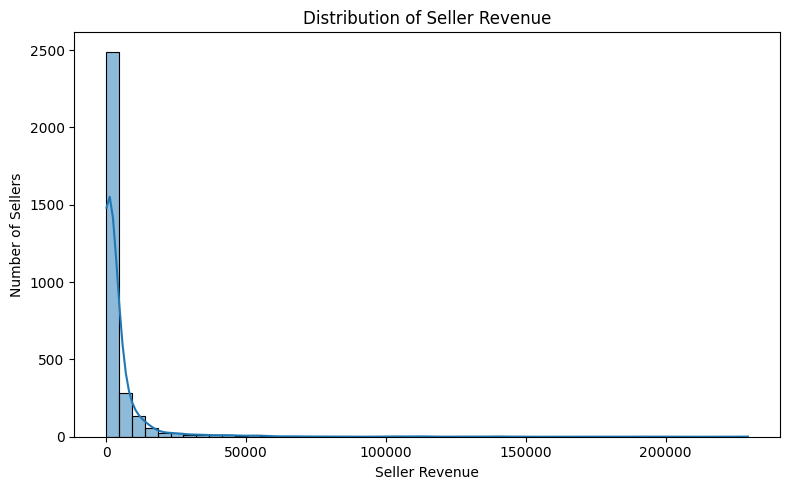

In [28]:
plt.figure(figsize=(8, 5))

sns.histplot(
    sellers["seller_revenue"],
    bins=50,
    kde=True
)

plt.title("Distribution of Seller Revenue")
plt.xlabel("Seller Revenue")
plt.ylabel("Number of Sellers")

plt.tight_layout()
plt.show()

In [ ]:
#BIVARIATE ANALYSIS

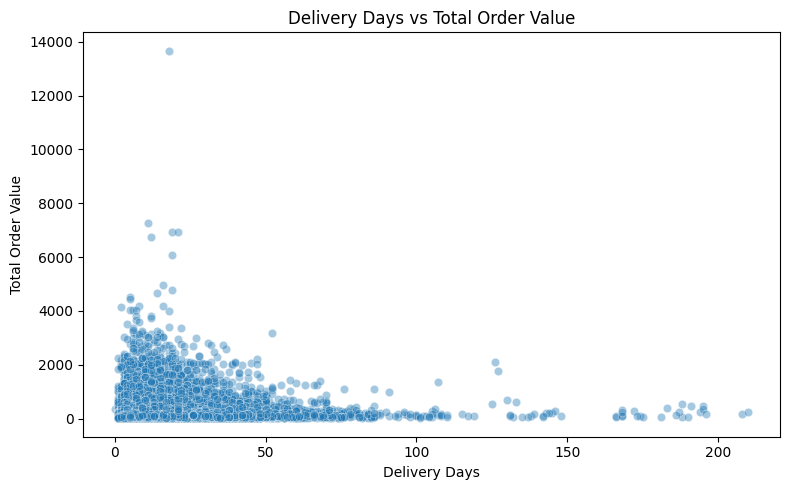

In [29]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=orders,
    x="delivery_days",
    y="total_order_value",
    alpha=0.4
)

plt.title("Delivery Days vs Total Order Value")
plt.xlabel("Delivery Days")
plt.ylabel("Total Order Value")

plt.tight_layout()
plt.show()

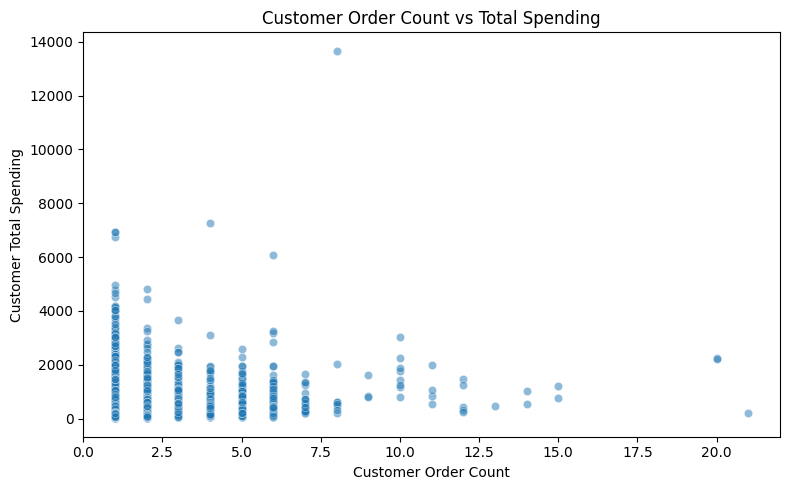

In [30]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=customers,
    x="customer_order_count",
    y="customer_total_spending",
    alpha=0.5
)

plt.title("Customer Order Count vs Total Spending")
plt.xlabel("Customer Order Count")
plt.ylabel("Customer Total Spending")

plt.tight_layout()
plt.show()

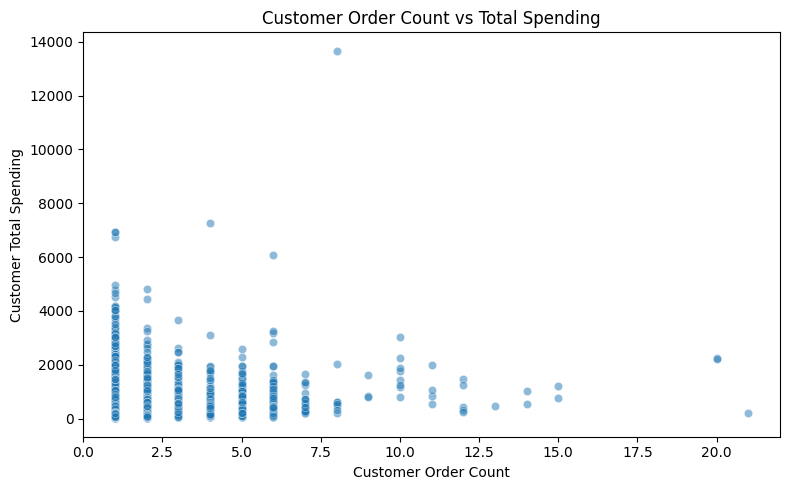

In [31]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=customers,
    x="customer_order_count",
    y="customer_total_spending",
    alpha=0.5
)

plt.title("Customer Order Count vs Total Spending")
plt.xlabel("Customer Order Count")
plt.ylabel("Customer Total Spending")

plt.tight_layout()
plt.show()

In [ ]:
# MULTI VARIATE ANALYSIS

In [36]:
orders["delivery_status"] = orders["delivery_delay"].apply(
    lambda x: "Delayed" if x > 0 else "On Time"
)

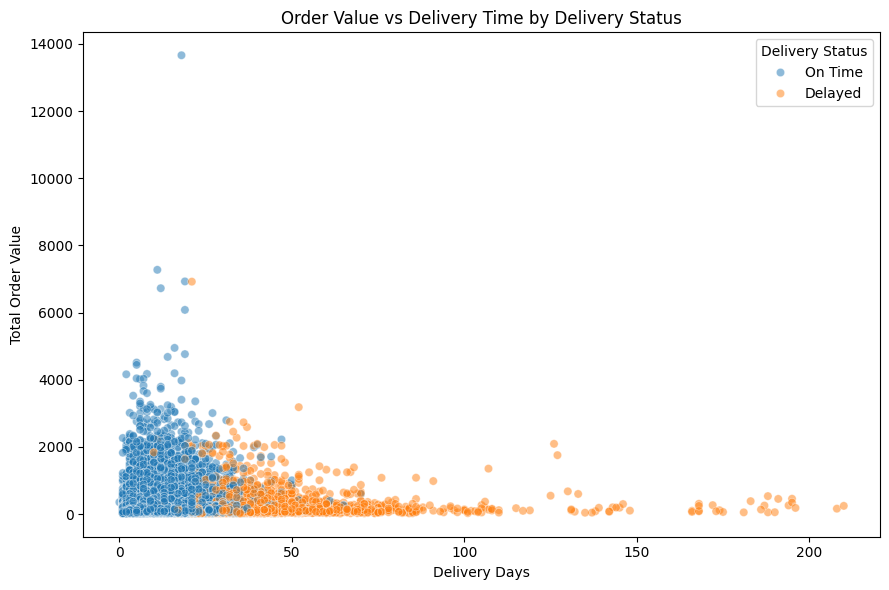

In [37]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=orders,
    x="delivery_days",
    y="total_order_value",
    hue="delivery_status",
    alpha=0.5
)

plt.title("Order Value vs Delivery Time by Delivery Status")
plt.xlabel("Delivery Days")
plt.ylabel("Total Order Value")
plt.legend(title="Delivery Status")

plt.tight_layout()
plt.show()

In [39]:
orders_raw = pd.read_csv(
    "../data/cleaned/olist_orders_dataset.csv",
    parse_dates=["order_purchase_timestamp"]
)

In [40]:
orders_raw["purchase_month"] = (
    orders_raw["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

In [41]:
monthly_sales = (
    orders_raw[
        ["order_id", "purchase_month"]
    ]
    .merge(
        orders[
            ["order_id", "total_order_value"]
        ],
        on="order_id",
        how="left"
    )
    .groupby("purchase_month", as_index=False)
    .agg(
        revenue=("total_order_value", "sum"),
        order_count=("order_id", "nunique")
    )
)

In [42]:
monthly_sales["average_order_value"] = (
    monthly_sales["revenue"]
    / monthly_sales["order_count"]
)

In [43]:
display(monthly_sales.head())

,purchase_month,revenue,order_count,average_order_value
0,2016-09,354.75,4,88.687500
1,2016-10,56808.84,324,175.335926
2,2016-12,19.62,1,19.620000
3,2017-01,137188.49,800,171.485613
4,2017-02,286280.62,1780,160.831809


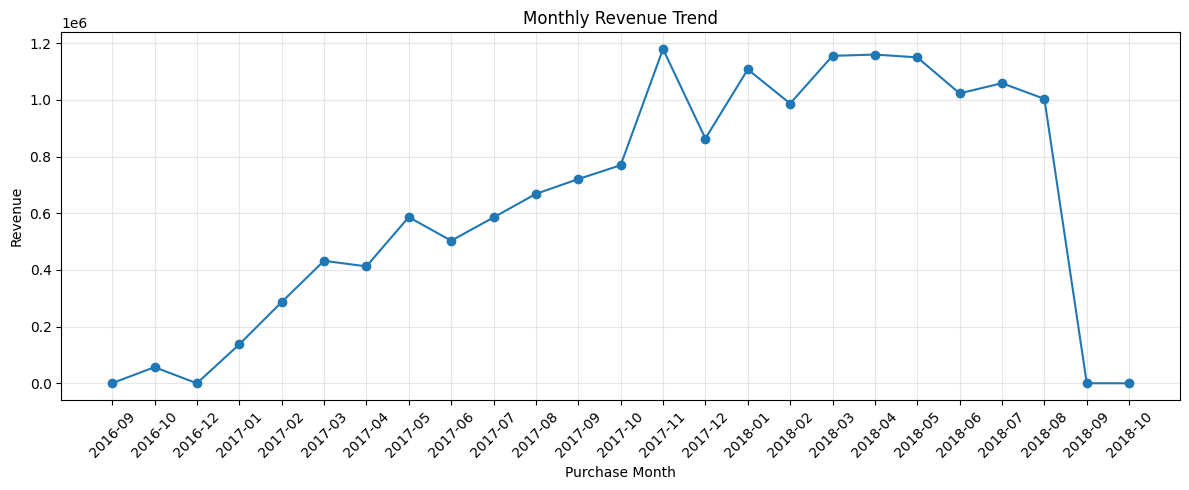

In [44]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["purchase_month"],
    monthly_sales["revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Purchase Month")
plt.ylabel("Revenue")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

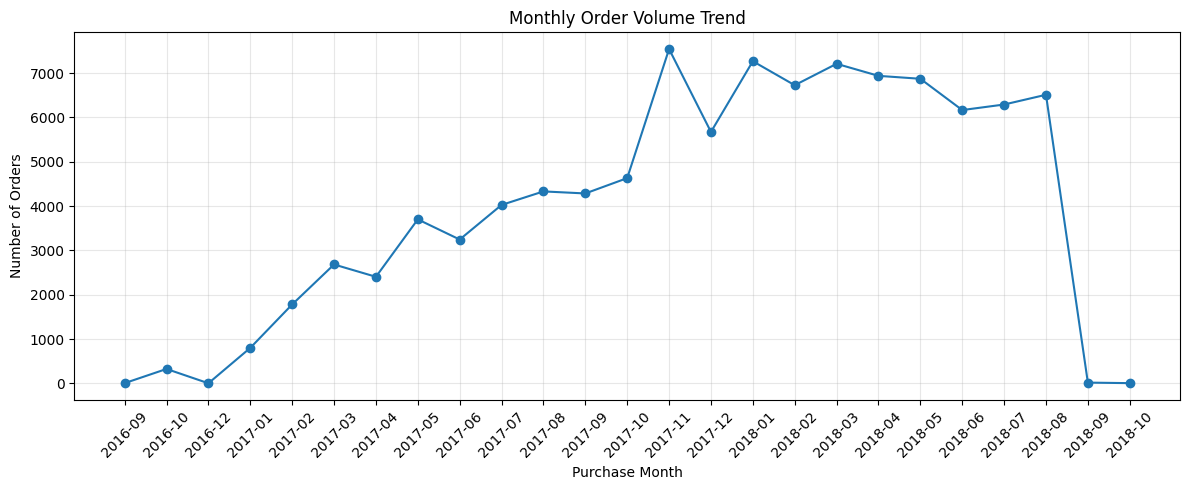

In [45]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["purchase_month"],
    monthly_sales["order_count"],
    marker="o"
)

plt.title("Monthly Order Volume Trend")
plt.xlabel("Purchase Month")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

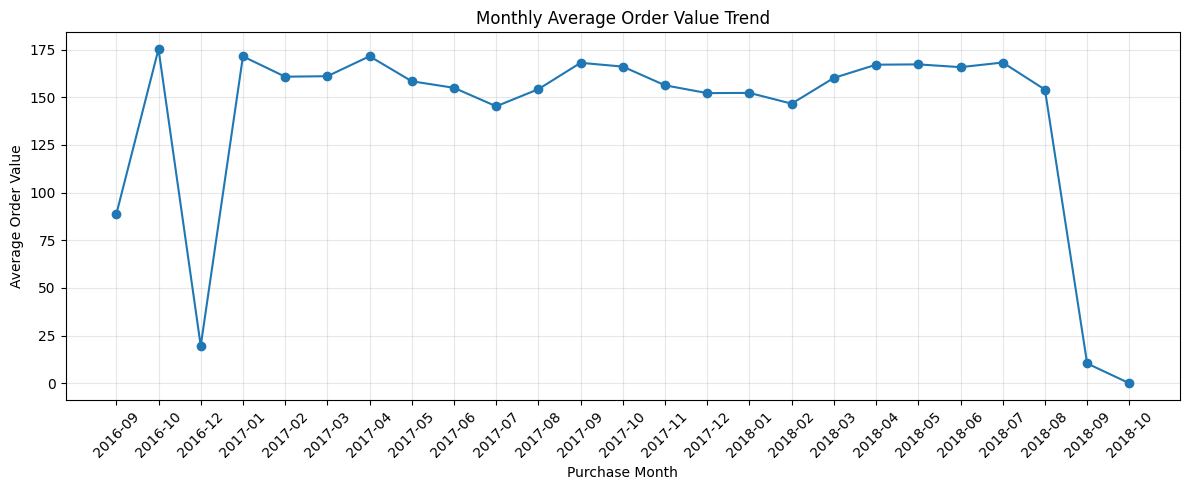

In [47]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["purchase_month"],
    monthly_sales["average_order_value"],
    marker="o"
)

plt.title("Monthly Average Order Value Trend")
plt.xlabel("Purchase Month")
plt.ylabel("Average Order Value")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# CORRELATION ANALYSIS

In [49]:
order_corr = orders[
    [
        "total_order_value",
        "delivery_days",
        "delivery_delay"
    ]
].corr()

display(order_corr)

,total_order_value,delivery_days,delivery_delay
total_order_value,1.000000,0.069854,-0.017702
delivery_days,0.069854,1.000000,0.607665
delivery_delay,-0.017702,0.607665,1.000000


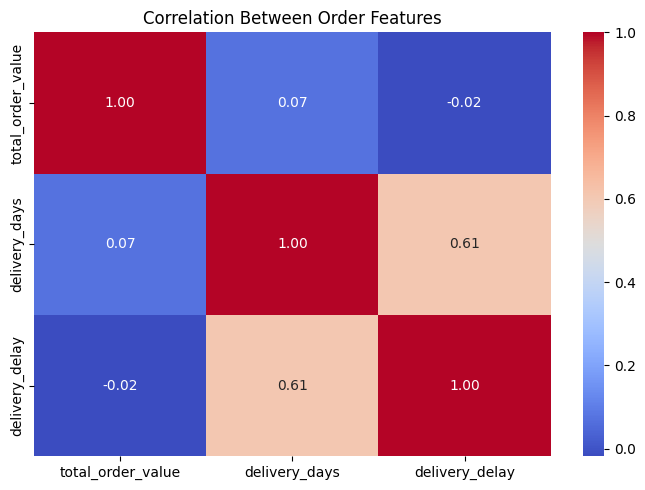

In [50]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    order_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Between Order Features")

plt.tight_layout()
plt.show()

In [51]:
customer_corr = customers[
    [
        "customer_order_count",
        "customer_total_spending",
        "average_order_value"
    ]
].corr()

display(customer_corr)

,customer_order_count,customer_total_spending,average_order_value
customer_order_count,1.000000,0.189155,0.189155
customer_total_spending,0.189155,1.000000,1.000000
average_order_value,0.189155,1.000000,1.000000


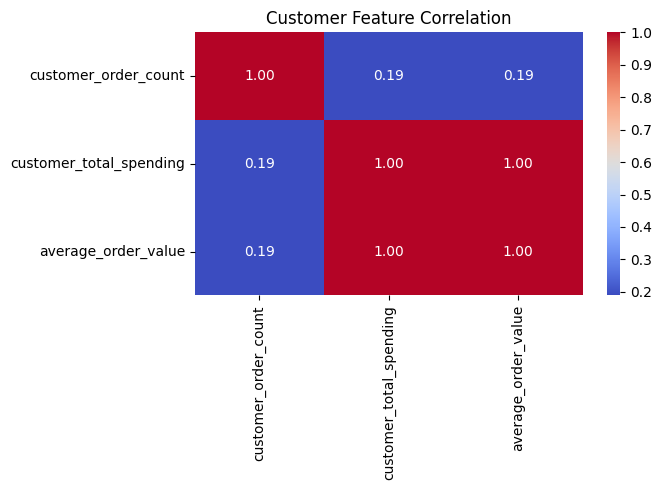

In [52]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    customer_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Customer Feature Correlation")

plt.tight_layout()
plt.show()

In [53]:
seller_corr = sellers[
    [
        "seller_revenue",
        "seller_order_count"
    ]
].corr()

display(seller_corr)

,seller_revenue,seller_order_count
seller_revenue,1.000000,0.799702
seller_order_count,0.799702,1.000000


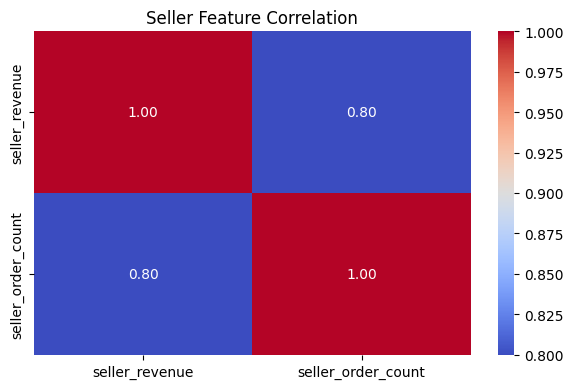

In [54]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    seller_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Seller Feature Correlation")

plt.tight_layout()
plt.show()

In [ ]:
# DISTRIBUTION ANALYSIS

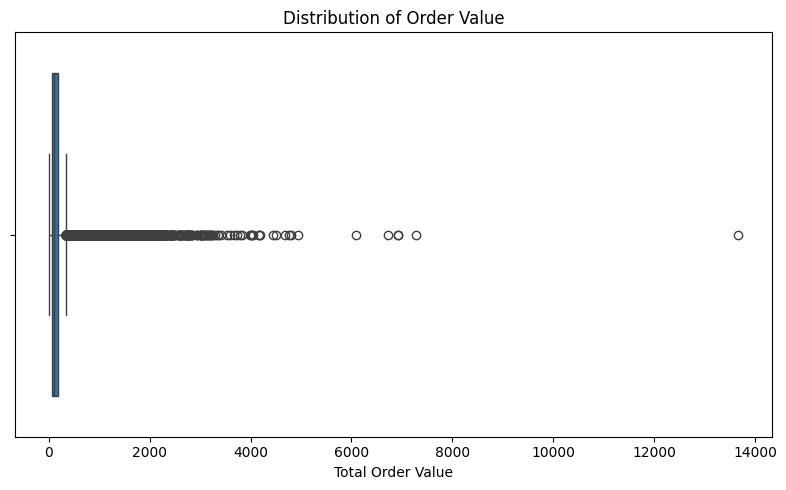

In [55]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x=orders["total_order_value"]
)

plt.title("Distribution of Order Value")
plt.xlabel("Total Order Value")

plt.tight_layout()
plt.show()

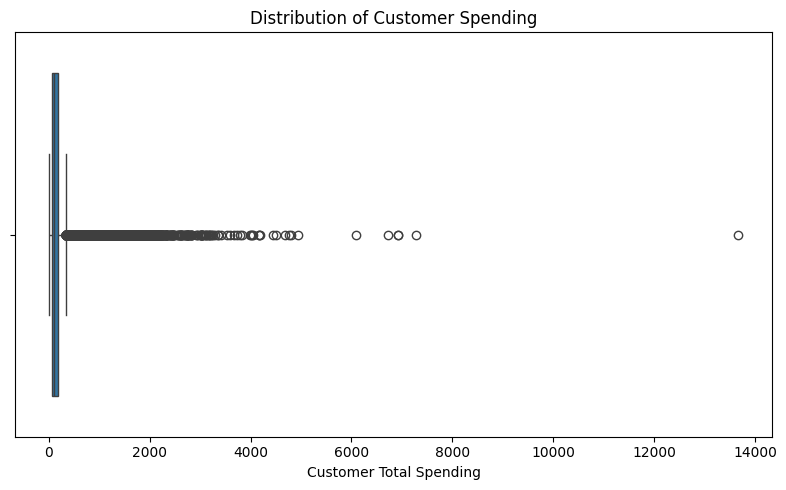

In [56]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x=customers["customer_total_spending"]
)

plt.title("Distribution of Customer Spending")
plt.xlabel("Customer Total Spending")

plt.tight_layout()
plt.show()

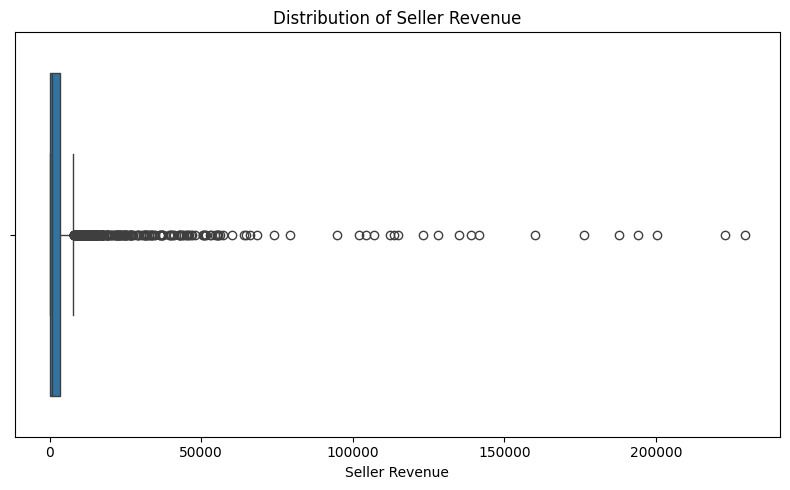

In [57]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x=sellers["seller_revenue"]
)

plt.title("Distribution of Seller Revenue")
plt.xlabel("Seller Revenue")

plt.tight_layout()
plt.show()